# First Practical Assignment

## Data Science and Engineering

### DESIGN OF A PARALLELISABLE AND SCALABLE IMAGE FILTERING FUNCTION

**Full name:** 

- Kelly Alejandra Hernández Moreno
    
**NIA:** 

- 100553651 

In [6]:
import numpy as np
import multiprocessing as mp
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cProfile

In [7]:
# IMPORT HERE YOU LIBRARIES
import os
import time
from pprint import pprint      # the EVALUATION section calls pprint(vars(_statistics))

# Our functions live in filters.py (same folder). With the "spawn" start method
# (Windows / Jupyter) the Pool workers must import them from a module: functions
# defined inside the notebook cannot be found by the worker processes.
from filters import image_filter, parallel_filtering
import filters                 # sequential reference (Part A) and helpers, for the extra tests

In [8]:
F_IMAGE1="images/chess.jpg"           #<DEFINE HERE WHICH IMAGE YOU WANTS TO LOAD
F_IMAGE2="images/cloudsonjupi.jpg"    #<DEFINE HERE WHICH IMAGE YOU WANTS TO LOAD

In [9]:
image1= np.array(Image.open(F_IMAGE1))
image2= np.array(Image.open(F_IMAGE2))

In [10]:
NUMPROCESS=4

# WRITE YOUR CODE AFTER THIS CELL

After this cell, use the preloaded image defined in the F_IMAGE variable, select two predefined filters, and apply them to the image using NUMPROCESS processors. Check the results.


Gaussian parallel == sequential: True
Sharpen  parallel == sequential: True
Same shape and type as the input: True uint8


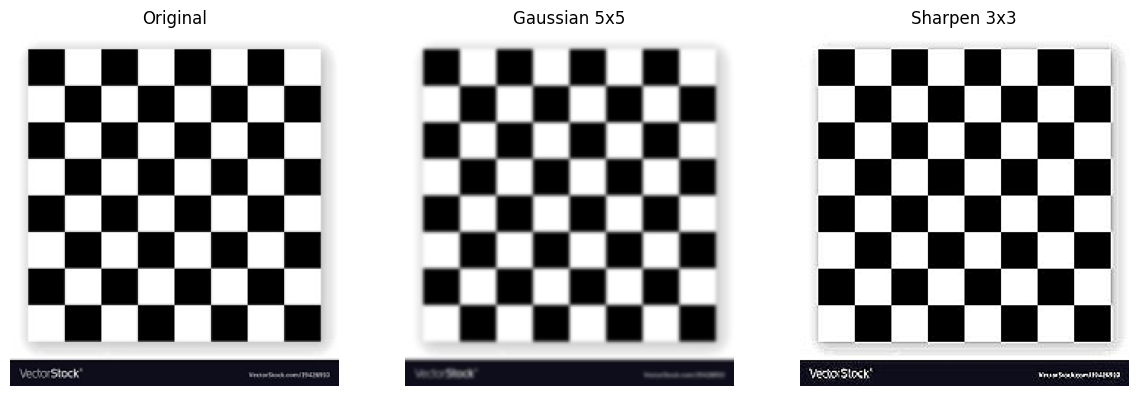

In [11]:
#YOUR CODE MUST BE START HERE

# Two predefined masks from the guide, applied to the preloaded image with NUMPROCESS processes.
gaussian_5 = np.outer([1, 4, 6, 4, 1], [1, 4, 6, 4, 1])     # sum 256 -> normalised inside image_filter
sharpen = np.array([[0, -1, 0],
                    [-1, 5, -1],
                    [0, -1, 0]])

# Both filters at the same time (each one with NUMPROCESS processes), correlation, saturation.
img1_gauss, img1_sharp = parallel_filtering(image1, gaussian_5, sharpen, NUMPROCESS, 0, 0)

# Check: the parallel result must be identical to the sequential reference (Part A).
print("Gaussian parallel == sequential:", np.array_equal(img1_gauss, filters.filter_sequential(image1, gaussian_5, 0, 0)))
print("Sharpen  parallel == sequential:", np.array_equal(img1_sharp, filters.filter_sequential(image1, sharpen, 0, 0)))
print("Same shape and type as the input:", img1_gauss.shape == image1.shape, img1_gauss.dtype)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, im, title in zip(axes, [image1, img1_gauss, img1_sharp], ["Original", "Gaussian 5x5", "Sharpen 3x3"]):
    ax.imshow(im); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

In [12]:
F_IMAGE1_PATH = F_IMAGE1
F_IMAGE1 = image1

#YOUR CODE MUST END HERE

# EVALUATION

In the following cells, we will call your functions to evaluate them.

In [13]:
filter_mask_id =np.array([
    [0,0,0,0,0],
    [0,0,0,0,0],
    [0,0,1,0,0],
    [0,0,0,0,0],
    [0,0,0,0,0]
])

In [14]:
%time
filtered_image1 = image_filter(F_IMAGE1,filter_mask_id,NUMPROCESS,0,0)

CPU times: total: 0 ns
Wall time: 4.29 μs


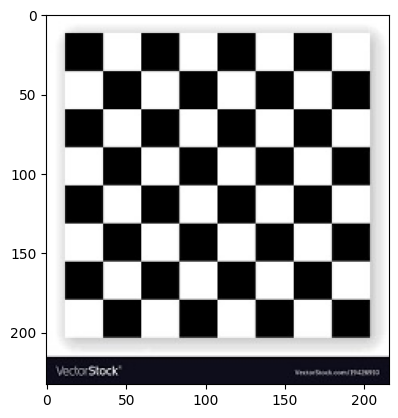

In [15]:
plt.figure()
plt.imshow(filtered_image1)

In [16]:
print(f"Identity Filter Works {np.allclose(F_IMAGE1,filtered_image1)}")

Identity Filter Works True


In [17]:
_statistics = %timeit -n 5 -r 2 -o image_filter(F_IMAGE1,filter_mask_id,NUMPROCESS,0,0)

835 ms ± 9.38 ms per loop (mean ± std. dev. of 2 runs, 5 loops each)


In [18]:
print(_statistics)

835 ms ± 9.38 ms per loop (mean ± std. dev. of 2 runs, 5 loops each)


In [19]:
pprint(vars(_statistics))

{'_precision': 3,
 'all_runs': [4.125829700031318, 4.219618300034199],
 'best': 0.8251659400062635,
 'compile_time': 0.0,
 'loops': 5,
 'repeat': 2,
 'timings': [0.8251659400062635, 0.8439236600068398],
 'worst': 0.8439236600068398}


# CASCADE FILTERING

In [20]:
filter_h=np.array([
    [1,0,-1],
    [2,0,-2],
    [1,0,-1]
])
filter_v=np.array([
    [1,2,1],
    [0,0,0],
    [-1,-2,-1]
])

In [21]:
%time
filtered_image1 = image_filter(F_IMAGE1,filter_h,NUMPROCESS,1,1)
filtered_image2 = image_filter(filtered_image1,filter_v,NUMPROCESS,1,1)

CPU times: total: 0 ns
Wall time: 2.86 μs


# PARALLEL FILTERING

In [22]:
%time
(filterd_image1,filtered_image2)=parallel_filtering(F_IMAGE1, filter_h, filter_v, NUMPROCESS, 1,1)

CPU times: total: 0 ns
Wall time: 3.1 μs


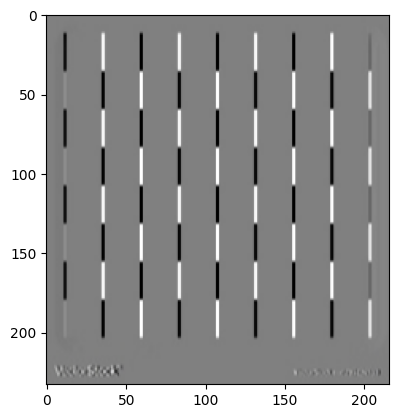

In [23]:
plt.figure()
plt.imshow(filtered_image1)

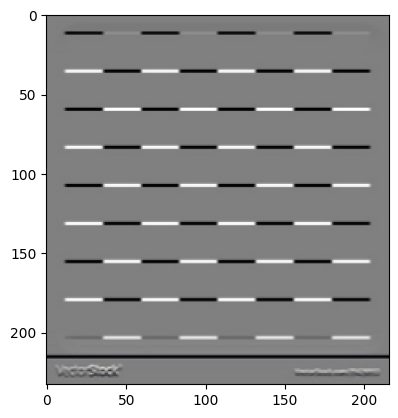

In [24]:
plt.figure()
plt.imshow(filtered_image2)

# Visualisation
In these final cells, we take the filtered images stored in the multiprocessing.Vector variables filtered_image1_VECTOR and filtered_image2_VECTOR, convert them to NumPy arrays with the same shapes as the original images, and display the results.

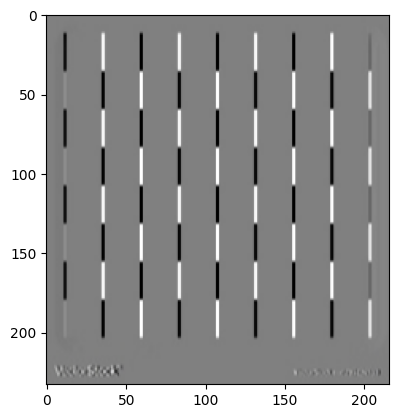

In [25]:
plt.figure()
plt.imshow(filtered_image1)

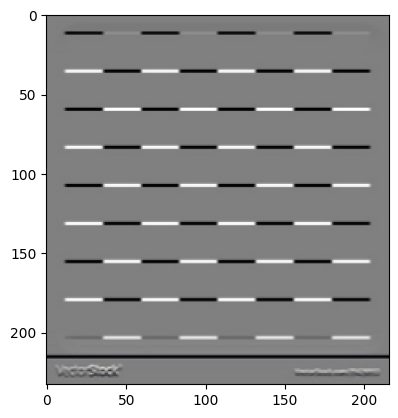

In [26]:
plt.figure()
plt.imshow(filtered_image2)

# ADD YOUR ADDITIONAL TESTS, ANALYSIS AND CONCLUSIONS AFTER THIS CELL

## 0. Notes on the provided notebook

The EVALUATION section has not been modified. These are the problems we found in the template and how we handled them:

| Where | Problem | What we did |
|---|---|---|
| Image loading cell | `image2` loaded `F_IMAGE1` instead of `F_IMAGE2` | Fixed (the cell is outside EVALUATION) |
| EVALUATION | `image_filter(F_IMAGE1, ...)` receives the file path, not the array | `image_filter` accepts both a path and a `np.ndarray` |
| EVALUATION | `np.allclose(F_IMAGE1, filtered_image1)` compares a string with an array and raises an error | At the end of our code cell `F_IMAGE1` is set to the loaded image, so the identity check runs |
| EVALUATION | `pprint` is not imported | Imported in the "IMPORT HERE YOUR LIBRARIES" cell |
| EVALUATION | `%time` alone on its line measures nothing (it should be `%%time`) | Our own timings are measured below with `time.perf_counter` |
| PARALLEL FILTERING | Typo `filterd_image1`: the next figure shows `filtered_image1` from the **cascade** cell, not from `parallel_filtering` | Taken into account when reading the figures; `parallel_filtering` is checked below |
| Visualisation | Mentions `filtered_image1_VECTOR` / `filtered_image2_VECTOR`, which do not exist |  |
| Guide | Says library `multiprocess`; the notebook imports `multiprocessing` | `filters.py` uses `multiprocess` if it is installed and falls back to `multiprocessing` |

**Conventions used in all our functions:** `is_conv = 0` → correlation, `is_conv = 1` → convolution (mask rotated 180°); `norm = 0` → round + saturate to 0–255, `norm = 1` → linear min–max rescaling (for masks that sum to 0).

In [27]:
# Masks used in this section (all from the guide)
g = np.array([1, 4, 6, 4, 1])
MASKS = {
    "identity 5x5": np.pad([[1]], 2),
    "mean 3x3":     np.ones((3, 3)),          # normalised (/9) inside image_filter
    "mean 5x5":     np.ones((5, 5)),          # normalised (/25)
    "gaussian 5x5": np.outer(g, g),           # normalised (/256)
    "laplacian":    np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]]),
    "sobel h":      filter_h,                 # from the CASCADE cell: responds to horizontal changes -> vertical edges
    "sobel v":      filter_v,                 # responds to vertical changes -> horizontal edges
    "sharpen":      np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),
}

checks = {}
def check(name, condition):
    """Stores the result of a test and prints it."""
    checks[name] = bool(condition)
    print(f"{'OK  ' if condition else 'FAIL'} {name}")

def show(images, titles, cols=None, size=4):
    """Shows several images side by side."""
    cols = cols or len(images)
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, im, title in zip(axes.flat, images, titles):
        ax.imshow(im, cmap="gray" if im.ndim == 2 else None, vmin=0, vmax=255)
        ax.set_title(title)
    plt.tight_layout(); plt.show()

print("Processes per filter (NUMPROCESS):", NUMPROCESS, "| CPUs in this machine:", os.cpu_count())
print("Multiprocessing library used by filters.py:", filters.mp.__name__)

Processes per filter (NUMPROCESS): 4 | CPUs in this machine: 32
Multiprocessing library used by filters.py: multiprocess


## 1. Mandatory tests (with the final parallel `image_filter`)

### 1.1 Identity mask: the output must be identical to the input, pixel by pixel

In [28]:
out = image_filter(image1, MASKS["identity 5x5"], NUMPROCESS, 0, 0)
check("identity 5x5 on image1: identical pixel by pixel", np.array_equal(out, image1))

grey = np.array(Image.open(F_IMAGE1_PATH).convert("L"))
out = image_filter(grey, np.ones((1, 1)), NUMPROCESS, 1, 0)
check("identity 1x1 on a greyscale image (2D in -> 2D out)", out.shape == grey.shape and np.array_equal(out, grey))

OK   identity 5x5 on image1: identical pixel by pixel
OK   identity 1x1 on a greyscale image (2D in -> 2D out)


### 1.2 Constant image 128 + mean 5×5: must stay 128 everywhere, borders included
If the borders were filled with zeros (zero padding) the corner would see only 9 real pixels out of 25 and would become 128·9/25 ≈ 46: a dark border. To show the difference, the same mask is also applied with zero padding, calling Part A's `filter_rows` directly.

OK   constant 128 + mean 5x5 -> 128 everywhere
Corners with replicate padding: 128 128 128 128
Corners with zero padding:     46 46 46 46 (dark border)


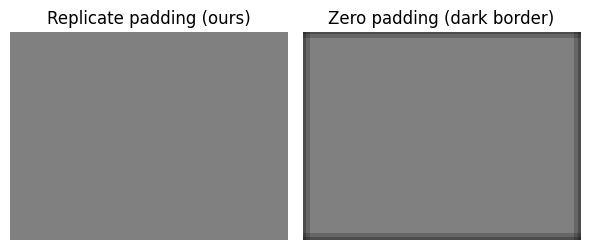

In [29]:
const128 = np.full((60, 80, 3), 128, dtype=np.uint8)
out = image_filter(const128, MASKS["mean 5x5"], NUMPROCESS, 0, 0)
check("constant 128 + mean 5x5 -> 128 everywhere", np.all(out == 128))
print("Corners with replicate padding:", out[0, 0, 0], out[0, -1, 0], out[-1, 0, 0], out[-1, -1, 0])

# Same filter but with ZERO padding, only to show what replication avoids
mask = filters.prepare_mask(MASKS["mean 5x5"], 0)
zero_padded = np.pad(const128.astype(np.float64), ((2, 2), (2, 2), (0, 0)))   # zeros around
S = np.zeros(const128.shape)
filters.filter_rows(zero_padded, mask, S, 0, const128.shape[0])
bad = filters.finalize(S, 0)
print("Corners with zero padding:    ", bad[0, 0, 0], bad[0, -1, 0], bad[-1, 0, 0], bad[-1, -1, 0], "(dark border)")
show([out, bad], ["Replicate padding (ours)", "Zero padding (dark border)"], size=3)

### 1.3 Very bright image (250) + sharpen: no dark pixels may appear
The sharpen mask sums 1, so on a constant image the exact result is 5·250 − 4·250 = 250. If the sum were accumulated in `uint8` it would wrap around (5·250 = 1250 → 1250 mod 256 = 226, and the subtractions would go below 0 and wrap again) and dark pixels would appear.

In [30]:
const250 = np.full((60, 80, 3), 250, dtype=np.uint8)
out = image_filter(const250, MASKS["sharpen"], NUMPROCESS, 0, 0)
print("min:", out.min(), " max:", out.max())
check("constant 250 + sharpen -> no dark pixels (all 250)", np.all(out == 250))

# Example from the guide: centre 200 surrounded by four 100 -> 5*200 - 4*100 = 600 -> saturated to 255
small = np.full((3, 3), 100, dtype=np.uint8); small[1, 1] = 200
check("guide example 600 -> saturated to 255", image_filter(small, MASKS["sharpen"], 1, 0, 0)[1, 1] == 255)

# What uint8 accumulation would do (wrap around instead of saturating)
u8 = np.array([250], dtype=np.uint8) + np.array([10], dtype=np.uint8)    # arrays wrap around silently
i32 = np.array([250], dtype=np.int32) + np.array([10], dtype=np.int32)
print("250 + 10 in uint8 =", u8[0], " | in int32 =", i32[0])

min: 250  max: 250
OK   constant 250 + sharpen -> no dark pixels (all 250)
OK   guide example 600 -> saturated to 255
250 + 10 in uint8 = 4  | in int32 = 260


### 1.4 Boundary replication demonstrated with a corner pixel
With a 5×5 mask centred on pixel (0, 0), the requested rows and columns −2, −1 are replaced by 0, so the corner pixel I(0, 0) appears 3 × 3 = 9 times inside the window. Below: the padded image, the count, and the value of O(0, 0) with the mean 5×5 mask computed by hand with the "adjust indices on the fly" rule of the guide, compared with `image_filter` (which uses the other method: extending the image before filtering).

In [31]:
ramp = (np.arange(1, 26).reshape(5, 5) * 10).astype(np.uint8)    # values 10, 20, ..., 250
padded = filters.pad_replicate(filters.to_3d(ramp), 2, 2)[:, :, 0].astype(int)
print("Image 5x5:\n", ramp, "\n\nWith replicate padding (a = b = 2):\n", padded)
print("\nTimes I(0,0) appears in the window of pixel (0,0):", np.sum(padded[0:5, 0:5] == ramp[0, 0]))
print("First row seen by the mask at the left border:", padded[2, 0:5], "(guide: 10, 10, 10, 20, 30)")

# O(0,0) by hand, clipping each coordinate separately (method 1 of the guide)
M, N = ramp.shape
acc = 0.0
for i in range(-2, 3):
    for j in range(-2, 3):
        r = min(max(0 + i, 0), M - 1)
        c = min(max(0 + j, 0), N - 1)
        acc += int(ramp[r, c]) / 25
out = image_filter(ramp, MASKS["mean 5x5"], NUMPROCESS, 0, 0)
print(f"\nO(0,0) by hand = {acc:.2f} -> rounded {int(np.floor(acc + 0.5))} | image_filter gives {out[0, 0]}")
check("corner pixel: hand computation == image_filter", int(np.floor(acc + 0.5)) == out[0, 0])
check("output has exactly the same size as the input", out.shape == ramp.shape)

Image 5x5:
 [[ 10  20  30  40  50]
 [ 60  70  80  90 100]
 [110 120 130 140 150]
 [160 170 180 190 200]
 [210 220 230 240 250]] 

With replicate padding (a = b = 2):
 [[ 10  10  10  20  30  40  50  50  50]
 [ 10  10  10  20  30  40  50  50  50]
 [ 10  10  10  20  30  40  50  50  50]
 [ 60  60  60  70  80  90 100 100 100]
 [110 110 110 120 130 140 150 150 150]
 [160 160 160 170 180 190 200 200 200]
 [210 210 210 220 230 240 250 250 250]
 [210 210 210 220 230 240 250 250 250]
 [210 210 210 220 230 240 250 250 250]]

Times I(0,0) appears in the window of pixel (0,0): 9
First row seen by the mask at the left border: [10 10 10 20 30] (guide: 10, 10, 10, 20, 30)

O(0,0) by hand = 46.00 -> rounded 46 | image_filter gives 46
OK   corner pixel: hand computation == image_filter
OK   output has exactly the same size as the input


## 2. Correlation vs convolution

Convolution is correlation with the mask rotated 180°. For symmetric masks (mean, Gaussian, Laplacian) the rotated mask is the same, so both give the same image. Sobel is antisymmetric: rotating it 180° is the same as multiplying it by −1, so convolution gives exactly −S. After the min–max rescaling, −S becomes the "negative" of the correlation image (255 − value, ±1 for rounding): the edges that were bright become dark and vice versa. For Sobel it is therefore important to state which operation was used; in this notebook it is indicated with `is_conv`.

OK   Sobel: correlation != convolution
OK   Sobel: convolution == 255 - correlation (+-1 rounding)
OK   Gaussian (symmetric): correlation == convolution


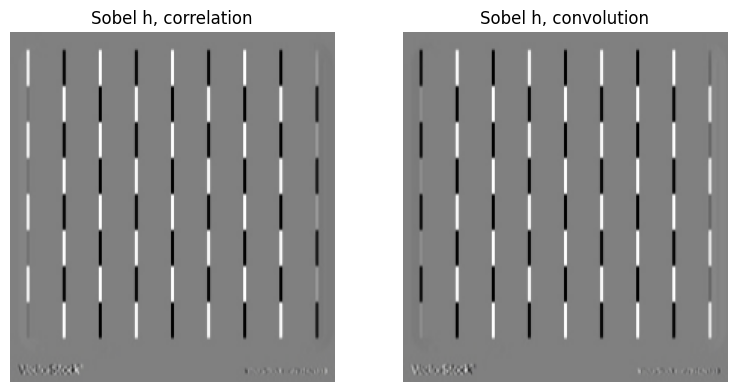

In [32]:
corr = image_filter(image1, MASKS["sobel h"], NUMPROCESS, 0, 1)
conv = image_filter(image1, MASKS["sobel h"], NUMPROCESS, 1, 1)
check("Sobel: correlation != convolution", not np.array_equal(corr, conv))
check("Sobel: convolution == 255 - correlation (+-1 rounding)",
      np.abs(conv.astype(int) - (255 - corr.astype(int))).max() <= 1)

g_corr = image_filter(image1, MASKS["gaussian 5x5"], NUMPROCESS, 0, 0)
g_conv = image_filter(image1, MASKS["gaussian 5x5"], NUMPROCESS, 1, 0)
check("Gaussian (symmetric): correlation == convolution", np.array_equal(g_corr, g_conv))
show([corr, conv], ["Sobel h, correlation", "Sobel h, convolution"], size=4)

## 3. Several masks on real images, in parallel (`parallel_filtering`)

Each pair of masks is applied to the **original** image at the same time with `parallel_filtering`, which launches two `image_filter` calls with `NUMPROCESS` processes each (up to 2·`NUMPROCESS` worker processes). Edge masks (sum 0) use `norm = 1`; the rest use `norm = 0`.

parallel_filtering(mean 5x5, gaussian 5x5): 4.10 s
OK   parallel_filtering == image_filter (mean 5x5)


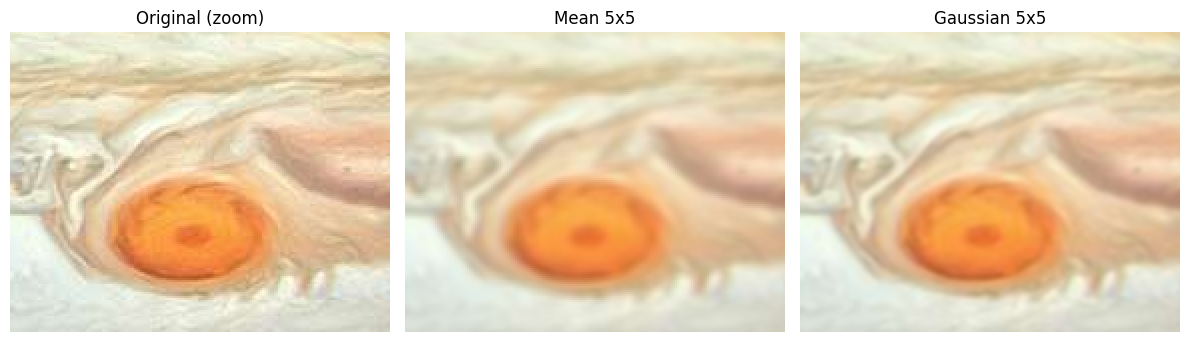

In [33]:
jupiter = image2                                                     # 480 x 751, colour
t0 = time.perf_counter()
j_mean, j_gauss = parallel_filtering(jupiter, MASKS["mean 5x5"], MASKS["gaussian 5x5"], NUMPROCESS, 0, 0)
print(f"parallel_filtering(mean 5x5, gaussian 5x5): {time.perf_counter() - t0:.2f} s")
check("parallel_filtering == image_filter (mean 5x5)", np.array_equal(j_mean, image_filter(jupiter, MASKS["mean 5x5"], NUMPROCESS, 0, 0)))

crop = (slice(250, 400), slice(330, 520))                            # zoom on the Great Red Spot
show([jupiter[crop], j_mean[crop], j_gauss[crop]], ["Original (zoom)", "Mean 5x5", "Gaussian 5x5"])

**Mean vs Gaussian.** Both smooth the image (they are low-pass filters that sum 1, so the mean brightness is preserved and they never saturate). The mean 5×5 gives the same weight to the 25 neighbours, so the cloud bands and the edge of the Great Red Spot lose more detail. The Gaussian gives most of the weight to the centre (36/256) and very little to the corners (1/256), so it blurs less for the same size and keeps the edges better.

parallel_filtering(sobel h, sobel v), norm=1: 3.19 s


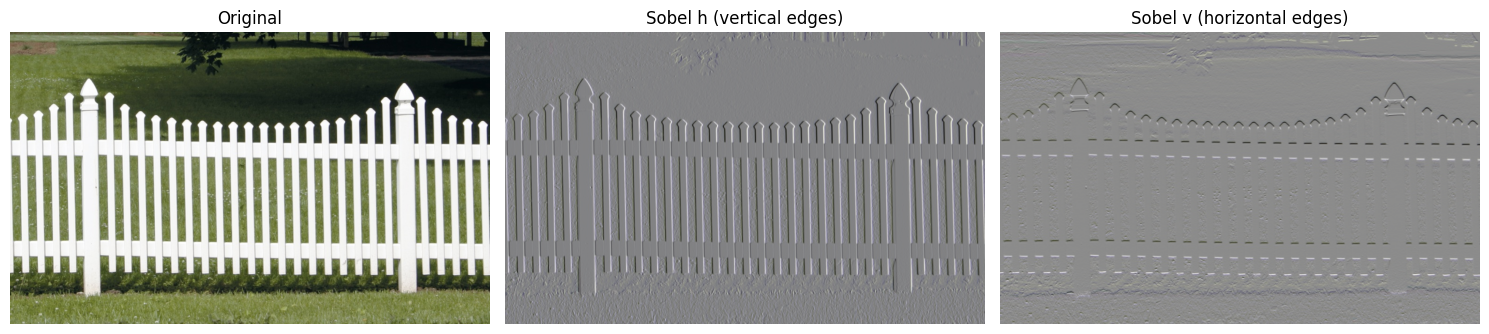

In [34]:
fence = np.array(Image.open("images/fence.jpg"))                     # 623 x 1024, colour
t0 = time.perf_counter()
f_h, f_v = parallel_filtering(fence, MASKS["sobel h"], MASKS["sobel v"], NUMPROCESS, 0, 1)
print(f"parallel_filtering(sobel h, sobel v), norm=1: {time.perf_counter() - t0:.2f} s")
show([fence, f_h, f_v], ["Original", "Sobel h (vertical edges)", "Sobel v (horizontal edges)"], size=5)

**Sobel horizontal vs vertical.** Both masks sum 0, so the result has positive and negative values and is rescaled min–max: grey (≈128) means "no edge", white and black are edges in opposite directions (dark → bright or bright → dark). `sobel h` measures the change from left to right, so it highlights the **vertical** edges: every picket of the fence appears as a white line and a black line. `sobel v` measures the change from top to bottom, so it highlights the **horizontal** edges: the two rails and the tops of the pickets. The grass has many small changes in all directions, which is why it looks like noise in both images.

parallel_filtering(sharpen, mean 3x3): 1.02 s  | image (640, 533)


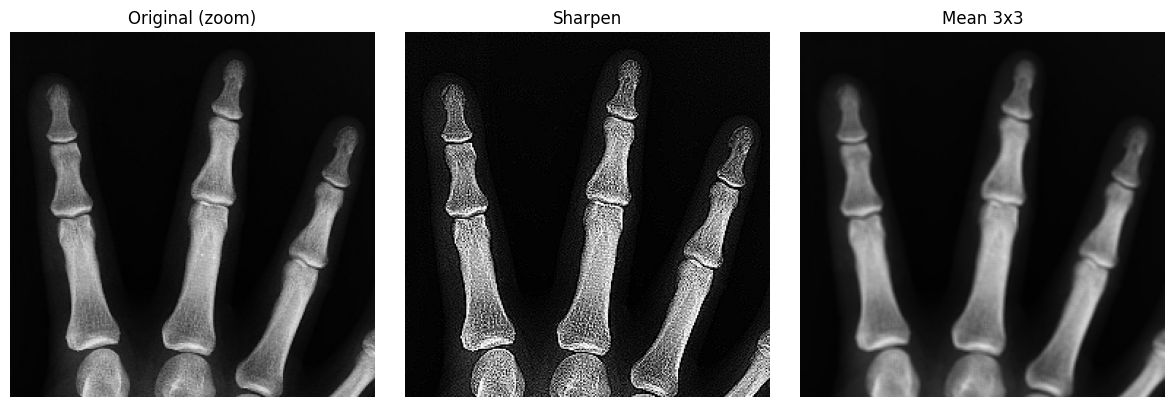

Pixels saturated at 255 by sharpen: 6982 | in the original: 6


In [35]:
hand = np.array(Image.open("images/hand-x-ray.jpg").convert("L"))[::3, ::3]   # greyscale, reduced to 640 x 533
t0 = time.perf_counter()
h_sharp, h_mean = parallel_filtering(hand, MASKS["sharpen"], MASKS["mean 3x3"], NUMPROCESS, 0, 0)
print(f"parallel_filtering(sharpen, mean 3x3): {time.perf_counter() - t0:.2f} s  | image {hand.shape}")
crop = (slice(80, 330), slice(150, 400))                             # zoom on the fingers
show([hand[crop], h_sharp[crop], h_mean[crop]], ["Original (zoom)", "Sharpen", "Mean 3x3"])
print("Pixels saturated at 255 by sharpen:", int(np.sum(h_sharp == 255)), "| in the original:", int(np.sum(hand == 255)))

**Sharpen vs mean.** Sharpen = identity + (−Laplacian): it adds to each pixel its difference with the neighbours, so it increases local contrast; the trabecular texture of the bones and the edges of the joints become more visible, but the noise of the X-ray is also amplified. Its maximum possible sum is 255·5 = 1275, so bright pixels next to darker ones go above 255 and are saturated (counted above). The mean 3×3 does the opposite: it removes noise and detail.

## 4. Filters in sequence (cascade)

In a cascade, the output of one filter (already rounded/saturated or rescaled to 0–255) is the input of the next one, and each stage applies its own boundary replication.

### 4.1 Gaussian → Laplacian reduces noise
The Laplacian is a second derivative, so it amplifies noise a lot. Gaussian noise (σ = 25) is added to the digits image, and the Laplacian is applied directly and after a Gaussian 5×5. To measure the noise, the standard deviation of the result is computed in a background area with no digits (top-left corner): without edges, that area should be a flat grey.

Background std, Laplacian directly:     9.9
Background std, Gaussian -> Laplacian:  5.1
OK   Gaussian before Laplacian reduces the noise in the background


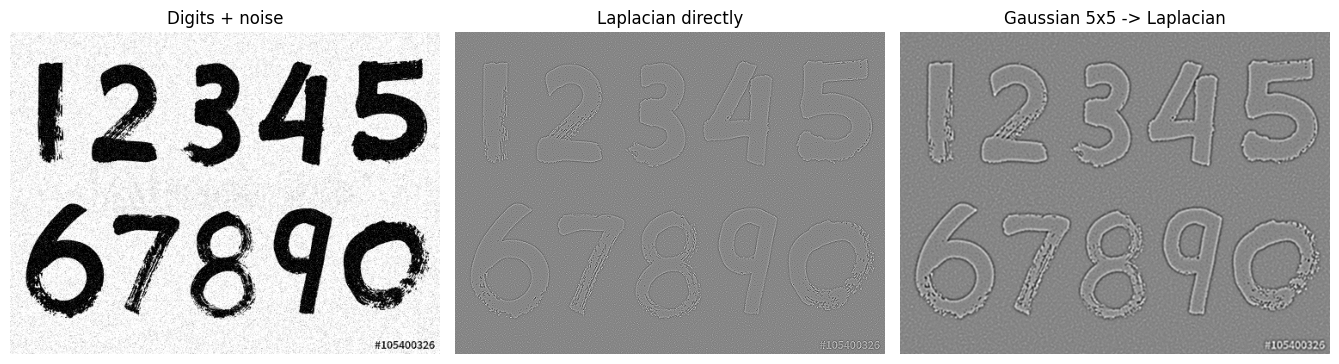

In [36]:
digits = np.array(Image.open("images/digits.jpg").convert("L"))       # greyscale 375 x 500
rng = np.random.default_rng(0)
noisy = np.clip(digits + rng.normal(0, 25, digits.shape), 0, 255).astype(np.uint8)

lap_direct = image_filter(noisy, MASKS["laplacian"], NUMPROCESS, 0, 1)
smoothed = image_filter(noisy, MASKS["gaussian 5x5"], NUMPROCESS, 0, 0)
lap_cascade = image_filter(smoothed, MASKS["laplacian"], NUMPROCESS, 0, 1)

bg = (slice(160, 200), slice(0, 20))                                 # background patch with no digits
print(f"Background std, Laplacian directly:     {lap_direct[bg].std():.1f}")
print(f"Background std, Gaussian -> Laplacian:  {lap_cascade[bg].std():.1f}")
check("Gaussian before Laplacian reduces the noise in the background", lap_cascade[bg].std() < lap_direct[bg].std())
show([noisy, lap_direct, lap_cascade], ["Digits + noise", "Laplacian directly", "Gaussian 5x5 -> Laplacian"], size=4.5)

Without smoothing, the Laplacian of the noisy image is almost all noise and the digits can barely be seen. With the Gaussian first, the noise is averaged out before the derivative and the outlines of the digits appear clearly. The price is that the edges are wider and less precise, because the Gaussian has also blurred them.

## 5. Performance analysis

### 5.1 Time and speed-up vs number of processes
Mean 5×5 on `image2` (480 × 751 × 3 ≈ 27 million multiplications). Each time is the best of 2 runs and includes creating the Pool and the shared memory. Speed-up = T(1) / T(p); efficiency = speed-up / p.

**Note:** the results depend on the machine. The numbers in the conclusions must be read from the output of this cell on the computer where the notebook is run.

filter_sequential (no Pool, no shared memory): 9.93 s

procs  time (s)  speed-up efficiency   serial fraction (Amdahl)
    1     10.33      1.00       1.00                        nan
    2      5.82      1.78       0.89                       0.13
    4      3.39      3.05       0.76                       0.10
    8      2.32      4.46       0.56                       0.11

Fastest: 8 processes (2.32 s) on a machine with 32 CPUs


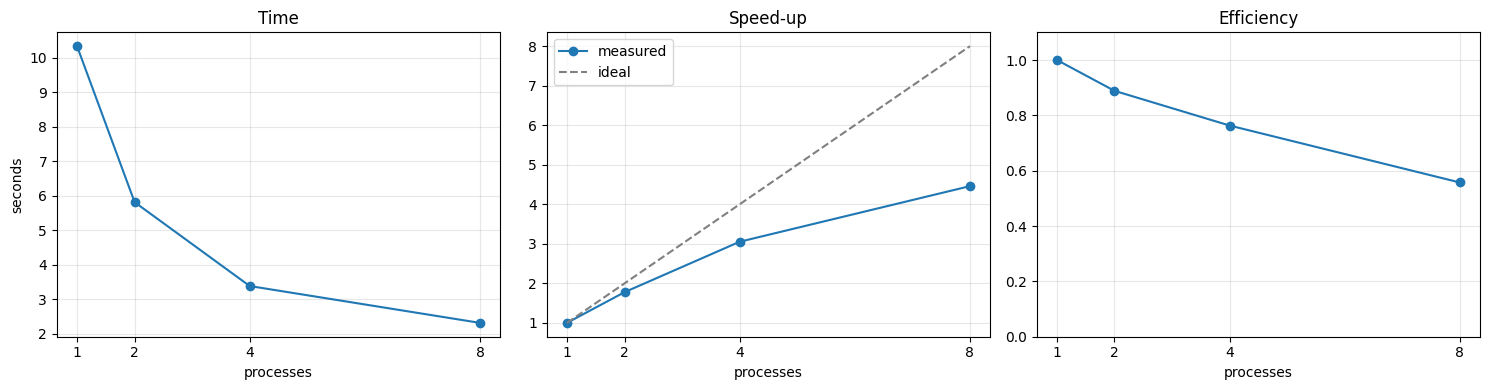

In [37]:
bench_img, bench_mask = image2, MASKS["mean 5x5"]
PROCS = sorted({p for p in (1, 2, 4, 8, os.cpu_count() or 1) if p <= 16})
REPEATS = 2

t0 = time.perf_counter()
filters.filter_sequential(bench_img, bench_mask, 0, 0)
t_seq = time.perf_counter() - t0
print(f"filter_sequential (no Pool, no shared memory): {t_seq:.2f} s\n")

times = []
for p in PROCS:
    runs = []
    for _ in range(REPEATS):
        t0 = time.perf_counter()
        image_filter(bench_img, bench_mask, p, 0, 0)
        runs.append(time.perf_counter() - t0)
    times.append(min(runs))

speedup = [times[0] / t for t in times]
print(f"{'procs':>5} {'time (s)':>9} {'speed-up':>9} {'efficiency':>10} {'serial fraction (Amdahl)':>26}")
for p, t, s in zip(PROCS, times, speedup):
    f = (p / s - 1) / (p - 1) if p > 1 else float("nan")   # Amdahl: S = 1 / (f + (1 - f) / p)
    print(f"{p:>5} {t:>9.2f} {s:>9.2f} {s / p:>10.2f} {f:>26.2f}")
print(f"\nFastest: {PROCS[int(np.argmin(times))]} processes ({min(times):.2f} s) on a machine with {os.cpu_count()} CPUs")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(PROCS, times, "o-"); ax[0].set_title("Time"); ax[0].set_ylabel("seconds")
ax[1].plot(PROCS, speedup, "o-", label="measured"); ax[1].plot(PROCS, PROCS, "--", color="grey", label="ideal")
ax[1].set_title("Speed-up"); ax[1].legend()
ax[2].plot(PROCS, [s / p for s, p in zip(speedup, PROCS)], "o-"); ax[2].set_title("Efficiency"); ax[2].set_ylim(0, 1.1)
for a in ax:
    a.set_xlabel("processes"); a.set_xticks(PROCS); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 5.2 Fixed cost of the parallelisation
On a tiny image (8 × 8) the filtering itself takes almost no time, so what is measured is the overhead: starting the processes of the Pool, creating the shared memory and sending the initializer data. This overhead grows with the number of processes and is part of why the speed-up is not linear.

In [38]:
tiny = np.zeros((8, 8, 3), dtype=np.uint8)
for p in PROCS:
    runs = []
    for _ in range(3):
        t0 = time.perf_counter()
        image_filter(tiny, MASKS["mean 5x5"], p, 0, 0)
        runs.append(time.perf_counter() - t0)
    print(f"{p:>2} processes: {min(runs) * 1000:7.1f} ms (overhead, almost no computation)")

 1 processes:   376.2 ms (overhead, almost no computation)
 2 processes:   353.6 ms (overhead, almost no computation)
 4 processes:   419.7 ms (overhead, almost no computation)
 8 processes:   489.6 ms (overhead, almost no computation)


## 6. Optional: comparison with a library filter

`scipy.ndimage.correlate` / `convolve` with `mode="nearest"` uses the same boundary rule (replicate the nearest border pixel). It is used here **only to check** our implementation, never inside `image_filter`. The same mask normalisation and the same final step (saturation or rescaling) are applied to the scipy result, so the only difference is the filtering itself.

In [39]:
try:
    from scipy import ndimage
except ImportError:
    ndimage = None
    print("scipy is not installed: comparison skipped")

def scipy_reference(image, mask, is_conv, norm):
    img = filters.to_3d(image).astype(np.float64)
    k = filters.prepare_mask(mask, 0)                      
    fn = ndimage.convolve if is_conv else ndimage.correlate
    S = np.stack([fn(img[:, :, c], k, mode="nearest") for c in range(img.shape[2])], axis=2)
    return filters.finalize(S, norm)

if ndimage is not None:
    worst = 0
    for name in ["mean 5x5", "gaussian 5x5", "sharpen", "laplacian", "sobel h"]:
        for is_conv in (0, 1):
            norm = 1 if np.isclose(MASKS[name].sum(), 0) else 0
            ours = image_filter(image1, MASKS[name], NUMPROCESS, is_conv, norm)
            d = np.abs(ours.astype(int) - scipy_reference(image1, MASKS[name], is_conv, norm).astype(int)).max()
            worst = max(worst, d)
            print(f"{name:13s} is_conv={is_conv} norm={norm}: max difference = {d}")
    check("same result as scipy.ndimage with mode='nearest' (max difference <= 1)", worst <= 1)

mean 5x5      is_conv=0 norm=0: max difference = 0
mean 5x5      is_conv=1 norm=0: max difference = 0
gaussian 5x5  is_conv=0 norm=0: max difference = 0
gaussian 5x5  is_conv=1 norm=0: max difference = 0
sharpen       is_conv=0 norm=0: max difference = 0
sharpen       is_conv=1 norm=0: max difference = 0
laplacian     is_conv=0 norm=1: max difference = 0
laplacian     is_conv=1 norm=1: max difference = 0
sobel h       is_conv=0 norm=1: max difference = 0
sobel h       is_conv=1 norm=1: max difference = 0
OK   same result as scipy.ndimage with mode='nearest' (max difference <= 1)


A difference of 0 means identical images. A difference of 1 could only happen in a pixel whose exact value is x.5, where the order of the floating-point additions may move it to one side or the other when rounding.

## 7. Conclusions

### Design decisions (group)

- **Algorithm.** `image_filter` computes the correlation formula of the guide (or the convolution, rotating the mask 180°, when `is_conv = 1`). The image is converted to `float64` before operating, so no overflow can happen; the mask is validated (2D, odd dimensions from 1 to 5) and normalised when its sum is neither 0 nor 1. The output is a new image: the input is never written.
- **Borders.** We chose the "extend the image before filtering" method: the image is padded with `a` rows and `b` columns copied from the nearest border, and only the original area is filtered. The output therefore has exactly the size of the input, and tests 1.2 and 1.4 show that there is no dark border and that the corner pixel is counted 9 times with a 5×5 mask.
- **Saturation and rescaling.** Values are rounded and saturated to 0–255 only at the end of the full sum (`norm = 0`). For masks that sum 0, the sums are rescaled min–max (`norm = 1`). This is done in the main process after all the workers have finished, because it needs the minimum and maximum of the whole image, which no single worker has.
- **Medium-grained parallelism.** The rows are divided into `numprocs` contiguous strips, one task per process. One pixel per task (fine grain) would make the cost of sending and scheduling tasks much higher than the computation; the whole image in one task (coarse grain) would not use more than one core.
- **Shared memory and Pool.** The padded image and the output sums are `RawArray` blocks. Each process has its own memory space, so without shared memory every worker would receive a copy of the image and would have to send back its strip. The Pool `initializer` gives each worker numpy views of these blocks **once**, so each task only receives two integers (start and end row).
- **No lock is needed.** The input is only read; every output pixel belongs to exactly one strip and therefore has exactly one writer; and the min–max rescaling is done after `pool.map` has returned. There is no position that two processes write, or that one writes while another reads, so there is no race condition. For this reason `RawArray` (without lock) is used instead of `Array`, whose lock would only add synchronisation cost.
- **`parallel_filtering`** reuses `image_filter` twice, in two threads. Threads are used because Pool workers are daemonic processes and cannot create their own Pool; each thread only starts its Pool and waits, while the real work is done by the worker processes, so the GIL does not limit it. In total up to 2·`numprocs` processes work at once.
- **Performance.** Performance. On our machine (32 CPUs), the fastest run was with 8 processes: 2.32 s vs 10.33 s with 1 process, a speed-up of 4.46 (efficiency 0.56). The speed-up is below the ideal because of the overhead of starting the Pool processes and copying the image to shared memory (section 5.2), and because loading, padding and finalize run in a single process (Amdahl’s law; the estimated serial fraction is about 0.1). The explicit Python loops make the filter slow (M·N·m·n multiplications per channel); a vectorised version would be much faster, but the explicit loops are the ones that show the algorithm.

### Personal conclusions

#### Member A — *Kelly Alejandra Hernández Moreno*

My part was the sequential version that the parallel code reuses. I wrote the mask validation, the preparation of the mask (180° rotation for convolution and normalisation when the sum is not 0 or 1), the replicate padding, `filter_rows` and `finalize`.

The most important thing I learned is that small details decide whether the result is correct. The first one is the data type because if the sum is computed in `uint8`, values above 255 wrap around and dark pixels appear in bright areas. Converting the image to `float64` before operating and saturating only at the end of the full sum solves this, and the test with the constant image 250 + sharpen proves it. The second one is the borders that with zero padding the corners become dark, while replicating the nearest pixel keeps a constant image at 128. I implemented the padding with `np.clip` on the row and column indices, which applies the rule of the guide to each coordinate separately, and I checked with a 5×5 example that the corner pixel appears 9 times in its window.

I also understood the difference between correlation and convolution which is that for symmetric masks like the Gaussian they give the same image, but for Sobel they do not, so it is important to say which one is used.

Finally, I designed `filter_rows` to work on a range of rows and to write into a separate output array, so that Member B could reuse it directly in each process without changing it. This showed me that is important to make previous decisions with the team before writing the code.

#### Member B — *Estrella Trabanca Pineda*

My part was the parallel version: `image_filter` and `parallel_filtering`. I put the padded image and the output sums in two `RawArray` blocks of shared memory, created the `Pool` with an `initializer` that gives each worker numpy views of those blocks and the mask, and split the rows into one contiguous strip per process. Each worker runs A's `filter_rows` on its strip, and `finalize` runs in the main process at the end. I also wrote `test_B.ipynb`, which checks that the parallel result is exactly the same as the sequential one for every mask, both values of `is_conv` and `norm`, and different numbers of processes.

The most important thing I learned is that processes do not share variables: each one has its own memory, so without shared memory a worker cannot see the image or write its result where the main process can read it. The `initializer` was also new for me: thanks to it, the image is not sent with every task, and each task only receives two integers.

Deciding about the lock made me think about who reads and who writes each position. The input is only read and the strips never overlap, so every output pixel has one writer, and the min–max rescaling is done after all the workers finish. A lock would only make it slower.

The hardest part was `parallel_filtering`. My first idea was to run the two `image_filter` calls inside a Pool, but Pool workers cannot create their own Pool, so I used two threads that only start the Pools and wait.

Finally, the time measurements on my laptop showed that more processes is not always better: with 4 processes the filter was about 1.9 times faster, but with 8 it was slower again, because creating processes and copying the image take a fixed time that is large for a small image. This is Amdahl's law in practice.

#### Member C — *(name)*
*(To be written by member C.)*